# Receptions

In [2]:
from pathlib import Path

import cmps
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from dotenv import find_dotenv, load_dotenv
from matplotlib import gridspec
from PIL import Image
from tqdm import tqdm

from nescafe23_fluctuations import tools

load_dotenv(find_dotenv())
package_dir = Path(tools.__file__).parent.parent.parent

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = 'retina'

In [5]:
dss = tools.open_receptions()

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 23/23 [00:19<00:00,  1.21it/s]


In [6]:
noise_powers_upper = []
noise_powers_upper_dB = []
noise_powers_lower = []
noise_powers_lower_dB = []

for k, ds in enumerate(dss):
    noise_slice = np.abs(ds.sel({"time": slice(90, 95)}))

    noise_power_upper = (
        np.sqrt(noise_slice[:32] ** 2)
        .mean(dim="time")
        .swap_dims({"hydrophone": "actual_depth"})
    )
    noise_power_lower = (
        np.sqrt(noise_slice[32:] ** 2)
        .mean(dim="time")
        .swap_dims({"hydrophone": "actual_depth"})
    )

    noise_power_upper_dB = 20 * np.log10(noise_power_upper)
    noise_power_lower_dB = 20 * np.log10(noise_power_lower)

    noise_powers_upper.append(noise_power_upper)
    noise_powers_upper_dB.append(noise_power_upper_dB)
    noise_powers_lower.append(noise_power_lower)
    noise_powers_lower_dB.append(noise_power_lower_dB)

/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountere

## GIF of receptions

In [10]:
reception_figures = []
for k in tqdm(range(23)):
    fig = plt.figure(figsize=(13, 6))

    fig.suptitle(f"Reception {k + 1}", fontsize=16)
    plt.subplot(2, 1, 1)
    im = (
        20 * np.log10(np.abs(dss[k][:32, :].swap_dims({"hydrophone": "actual_depth"})))
        - noise_power_upper_dB[k]
    ).plot(vmin=5, vmax=30, cmap=cmps.plasma_coolwarm(), add_colorbar=False)
    plt.xlim([100, 115])
    plt.ylim([600, 100])
    plt.xlabel("time [s]")
    plt.ylabel("depth [m]")

    plt.subplot(2, 1, 2)
    (
        20 * np.log10(np.abs(dss[k][32:, :].swap_dims({"hydrophone": "actual_depth"})))
        - noise_power_lower_dB[k]
    ).plot(vmin=5, vmax=30, cmap=cmps.plasma_coolwarm(), add_colorbar=False)
    plt.xlim([100, 115])
    plt.ylim([1300, 900])
    plt.xlabel("time [s]")
    plt.ylabel("depth [m]")

    plt.tight_layout()
    fig.subplots_adjust(right=0.9)
    # Add shared colorbar
    cbar = plt.colorbar(im, ax=fig.axes, label="snr [dB]", pad=0.02)

    fig.canvas.draw()
    # Fixed line - use buffer_rgba() and convert to RGB
    image = Image.frombuffer(
        "RGBA",
        fig.canvas.get_width_height(),
        fig.canvas.buffer_rgba(),
        "raw",
        "RGBA",
        0,
        1,
    )
    reception_figures.append(image.convert("RGB"))
    plt.close(fig)

reception_figures[0].save(
    f"{package_dir}/figures/auxiliary/receptions_animation.gif",
    save_all=True,
    append_images=reception_figures[1:],
    duration=200,
    loop=0,
)

  0%|          | 0/23 [00:00<?, ?it/s]/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
  4%|▍         | 1/23 [00:00<00:19,  1.11it/s]/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
  9%|▊         | 2/23 [00:01<00:18,  1.13it/s]/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
 13%|█▎        | 3/23 [00:02<00:17,  1.15it/s]/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*

In [11]:
reception_figures = []
for k in tqdm(range(23)):
    fig = plt.figure(figsize=(13, 6))

    fig.suptitle(f"Reception {k + 1}", fontsize=16)
    plt.subplot(2, 1, 1)
    im = (
        20 * np.log10(np.abs(dss[k][:32, :].swap_dims({"hydrophone": "actual_depth"})))
        - noise_power_upper_dB[k]
    ).plot(vmin=5, vmax=30, cmap=cmps.plasma_coolwarm(), add_colorbar=False)
    plt.xlim([100, 102])
    plt.ylim([600, 100])
    plt.xlabel("time [s]")
    plt.ylabel("depth [m]")

    plt.subplot(2, 1, 2)
    (
        20 * np.log10(np.abs(dss[k][32:, :].swap_dims({"hydrophone": "actual_depth"})))
        - noise_power_lower_dB[k]
    ).plot(vmin=5, vmax=30, cmap=cmps.plasma_coolwarm(), add_colorbar=False)
    plt.xlim([100, 102])
    plt.ylim([1300, 900])
    plt.xlabel("time [s]")
    plt.ylabel("depth [m]")

    plt.tight_layout()
    fig.subplots_adjust(right=0.9)
    # Add shared colorbar
    cbar = plt.colorbar(im, ax=fig.axes, label="snr [dB]", pad=0.02)

    fig.canvas.draw()
    # Fixed line - use buffer_rgba() and convert to RGB
    image = Image.frombuffer(
        "RGBA",
        fig.canvas.get_width_height(),
        fig.canvas.buffer_rgba(),
        "raw",
        "RGBA",
        0,
        1,
    )
    reception_figures.append(image.convert("RGB"))
    plt.close(fig)

reception_figures[0].save(
    f"{package_dir}/figures/auxiliary/receptions_animation_ducted.gif",
    save_all=True,
    append_images=reception_figures[1:],
    duration=200,
    loop=0,
)

  0%|          | 0/23 [00:00<?, ?it/s]/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
  4%|▍         | 1/23 [00:00<00:18,  1.19it/s]/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
  9%|▊         | 2/23 [00:01<00:17,  1.19it/s]/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
 13%|█▎        | 3/23 [00:02<00:16,  1.21it/s]/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*

## Mean Pulse

In [3]:
dss_interp = []
dss_upper_interp = []
for ds in tqdm(dss):
    dss_interp.append(
        np.abs(
            ds.swap_dims({"hydrophone": "actual_depth"})
            .rename({"actual_depth": "depth"})[32:]
            .interp({"depth": np.linspace(800, 1400, 50), "time": dss[0].time.values})
            .drop_vars(["nominal_depth"])
        )
    )

    dss_upper_interp.append(
        np.abs(
            ds.swap_dims({"hydrophone": "actual_depth"})
            .rename({"actual_depth": "depth"})[:32]
            .interp({"depth": np.linspace(100, 600, 50), "time": dss[0].time.values})
            .drop_vars(["nominal_depth"])
        )
    )

ds_interp = xr.concat(dss_interp, dim="Tx")
ds_interp_upper = xr.concat(dss_upper_interp, dim="Tx")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 23/23 [00:02<00:00,  9.67it/s]


In [4]:
mean_pulse_upper = ds_interp_upper.mean(dim="Tx")
mean_pulse_lower = ds_interp.mean(dim="Tx")

mean_pulse_upper_noise = 20 * np.log10(
    np.sqrt((mean_pulse_upper.sel({"time": slice(90, 95)}) ** 2).mean(dim="time"))
)
mean_pulse_lower_noise = 20 * np.log10(
    np.sqrt((mean_pulse_lower.sel({"time": slice(90, 95)}) ** 2).mean(dim="time"))
)

In [5]:
thetas = np.linspace(-40, 40, 200)
bf_upper = tools.ULA_conventional_beamform(
    dss[0][:32]
    .swap_dims({"hydrophone": "nominal_depth"})
    .rename({"nominal_depth": "depth"}),
    thetas,
)
bf_lower = tools.ULA_conventional_beamform(
    dss[0][32:]
    .swap_dims({"hydrophone": "nominal_depth"})
    .rename({"nominal_depth": "depth"}),
    thetas,
)

bf_upper_noise = 20 * np.log10(
    np.sqrt(np.abs(bf_upper.sel({"time": slice(90, 95)}) ** 2).mean(dim="time"))
)
bf_lower_noise = 20 * np.log10(
    np.sqrt(np.abs(bf_lower.sel({"time": slice(90, 95)}) ** 2).mean(dim="time"))
)

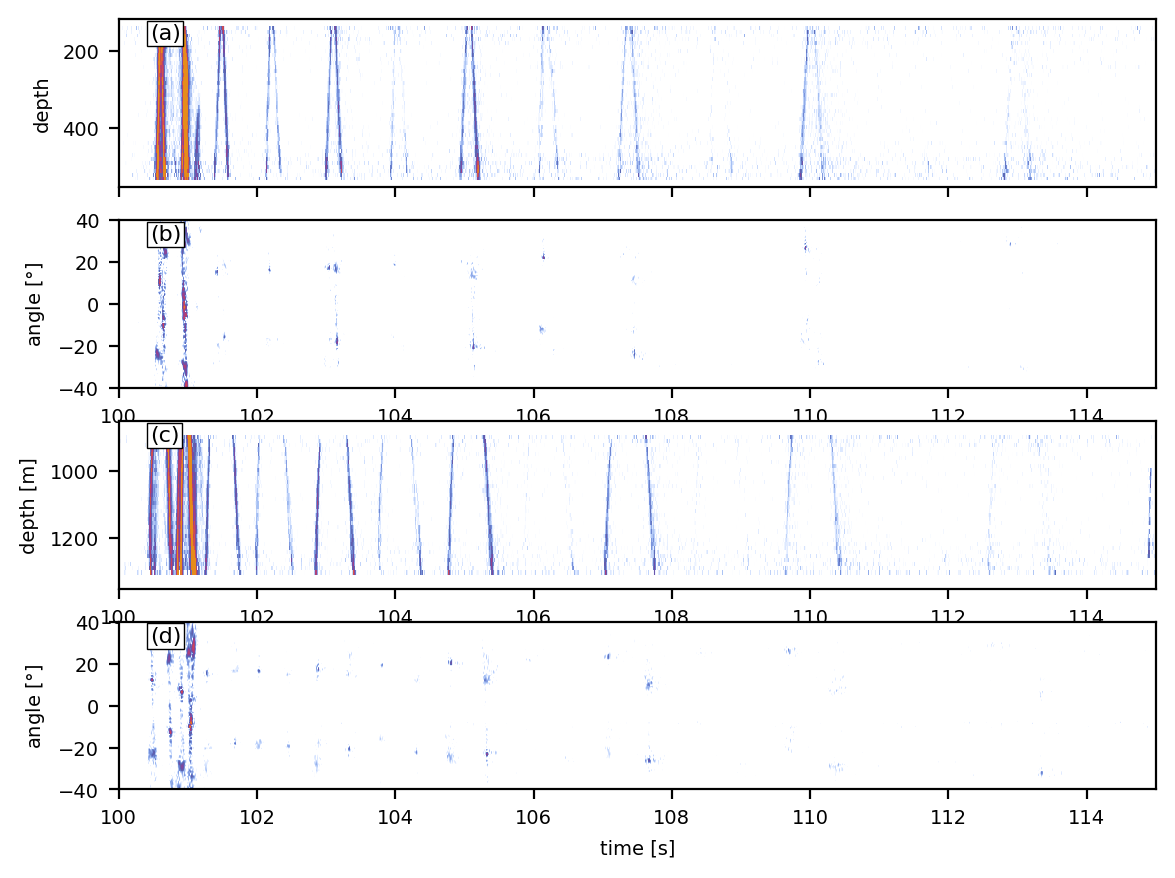

<Figure size 640x480 with 0 Axes>

In [6]:
plt.rcParams.update({"font.size": 7})
plt.rcParams.update({"text.usetex": False})
plt.rcParams.update({"font.family": "sans-serif"})

fig, axs = plt.subplots(4, 1, figsize=(6.69, 5))
axs = axs.flatten()

letters = ["(a)", "(b)", "(c)", "(d)"]

# add letters
for k, ax in enumerate(axs):
    ax.text(
        0.03,
        0.88,
        letters[k],
        transform=ax.transAxes,
        fontsize=8,
        zorder=100,
        bbox=dict(facecolor="white", edgecolor="k", pad=1, linewidth=0.5),
    )

snr_min = 2
snr_max = 20

plt.sca(axs[0])
(20 * np.log10(mean_pulse_upper) - mean_pulse_upper_noise).plot(
    x="time",
    vmin=snr_min,
    vmax=snr_max,
    cmap=cmps.plasma_coolwarm(),
    add_colorbar=False,
)
plt.xlim([100, 115])
plt.ylim([550, 120])

axs[0].set_xticklabels("")
plt.xlabel("")

plt.sca(axs[1])
(20 * np.log10(np.abs(bf_upper))).plot(
    x="time", vmin=120, cmap=cmps.plasma_coolwarm(), add_colorbar=False
)
plt.xlim([100, 115])
plt.ylim([-40, 40])
plt.xlabel("time [s]")
plt.ylabel("angle [$\\degree$]")


plt.sca(axs[2])
(20 * np.log10(mean_pulse_lower) - mean_pulse_lower_noise).plot(
    x="time",
    vmin=snr_min,
    vmax=snr_max,
    cmap=cmps.plasma_coolwarm(),
    add_colorbar=False,
)
plt.xlim([100, 115])
plt.ylim([1350, 850])
plt.xlabel("time [s]")
plt.ylabel("depth [m]")

plt.sca(axs[3])
(20 * np.log10(np.abs(bf_lower))).plot(
    x="time", vmin=120, cmap=cmps.plasma_coolwarm(), add_colorbar=False
)
plt.xlim([100, 115])
plt.ylim([-40, 40])
plt.xlabel("time [s]")
plt.ylabel("angle [$\\degree$]")

plt.figure()
plt.tight_layout()

(100.0, 102.0)

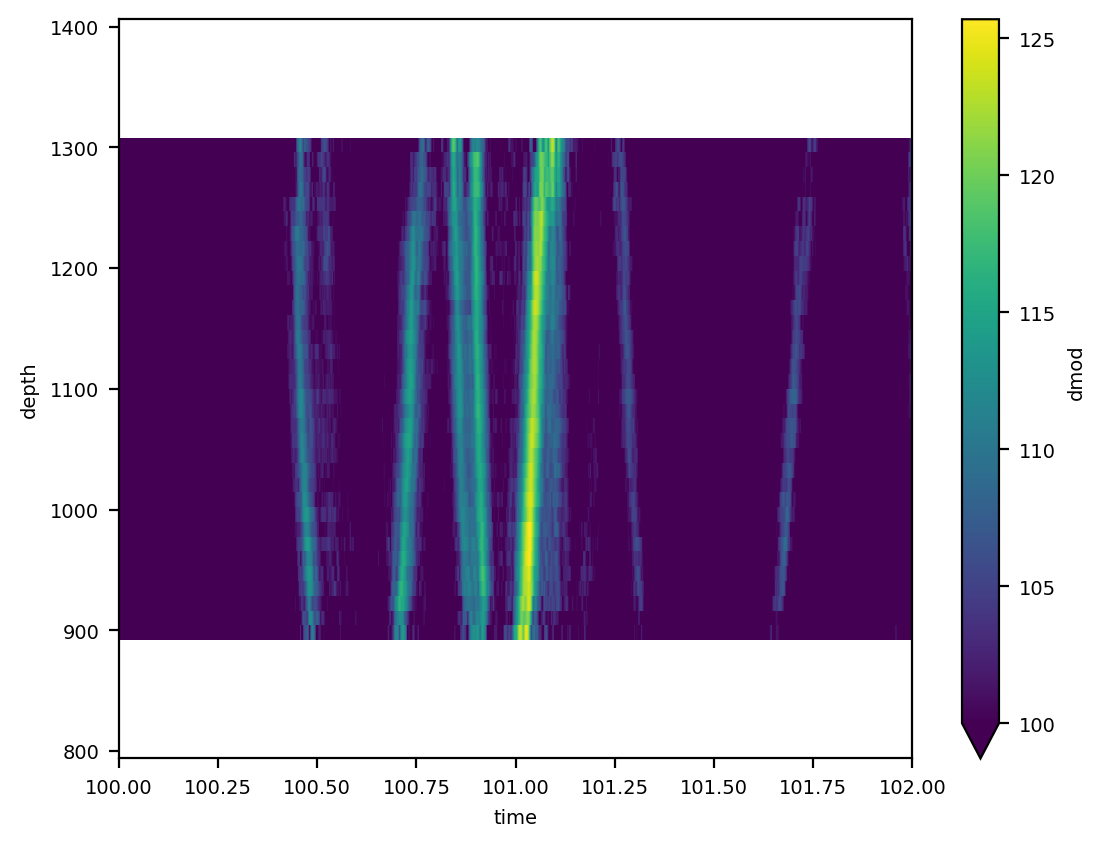

In [12]:
(20 * np.log10(mean_pulse_lower)).plot(vmin=100)
plt.xlim([100, 102])

In [14]:
thetas = np.linspace(-30, 30, 200)

mean_pulse_bf = tools.ULA_conventional_beamform(mean_pulse_lower, thetas)

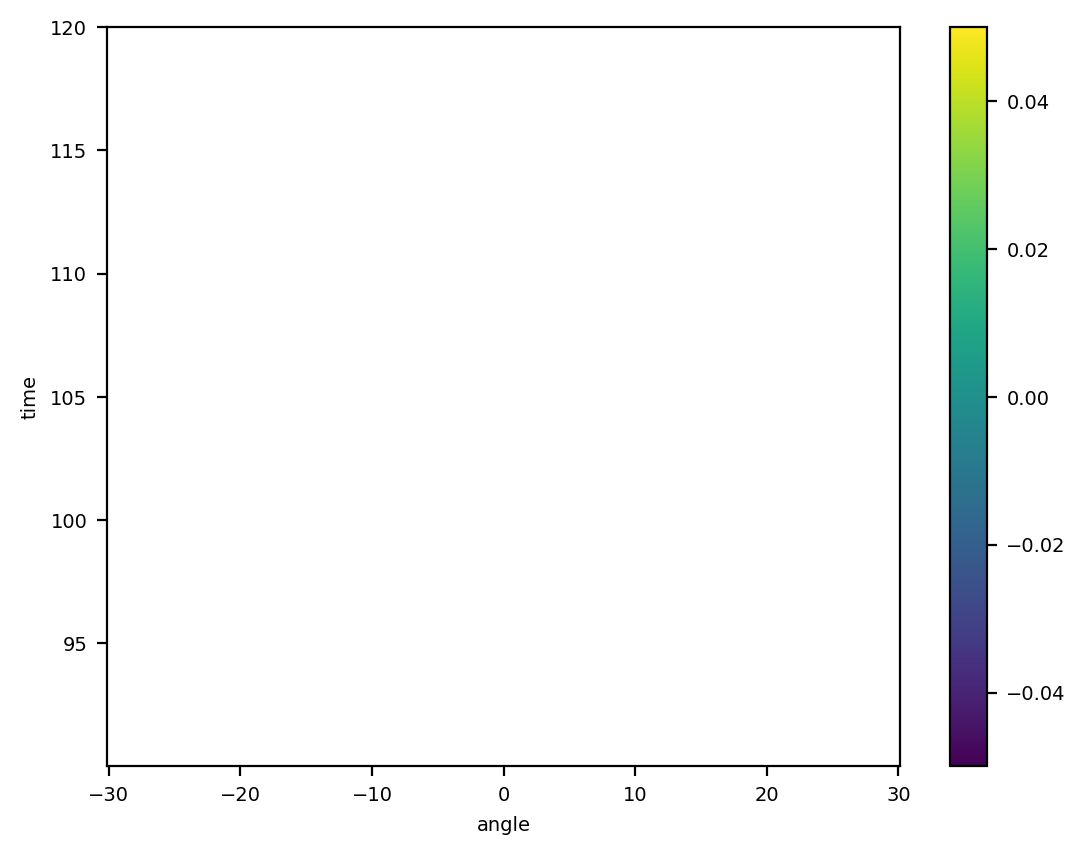

In [17]:
mean_pulse_bf.real.plot()

## Single Reception

In [7]:
single_rx_upper = dss[4][:32].swap_dims({"hydrophone": "actual_depth"})
single_rx_lower = dss[4][32:].swap_dims({"hydrophone": "actual_depth"})

single_rx_upper_nom = single_rx_upper.swap_dims({
    "actual_depth": "nominal_depth"
}).rename({"nominal_depth": "depth"})
single_rx_lower_nom = single_rx_lower.swap_dims({
    "actual_depth": "nominal_depth"
}).rename({"nominal_depth": "depth"})

In [12]:
thetas = np.linspace(-35, 35, 200)

bf_upper = tools.ULA_conventional_beamform(
    single_rx_upper_nom.sel({"time": slice(95, 115)}), thetas
)
bf_lower = tools.ULA_conventional_beamform(
    single_rx_lower_nom.sel({"time": slice(95, 115)}), thetas
)

In [13]:
bf_upper_noise_dB = 20 * np.log10(
    bf_upper.sel({"time": slice(95, 100)}).std(dim="time")
)
bf_lower_noise_dB = 20 * np.log10(
    bf_lower.sel({"time": slice(95, 100)}).std(dim="time")
)

/Users/john/Code/NESCAFE/nescafe_23_fluctuations/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)


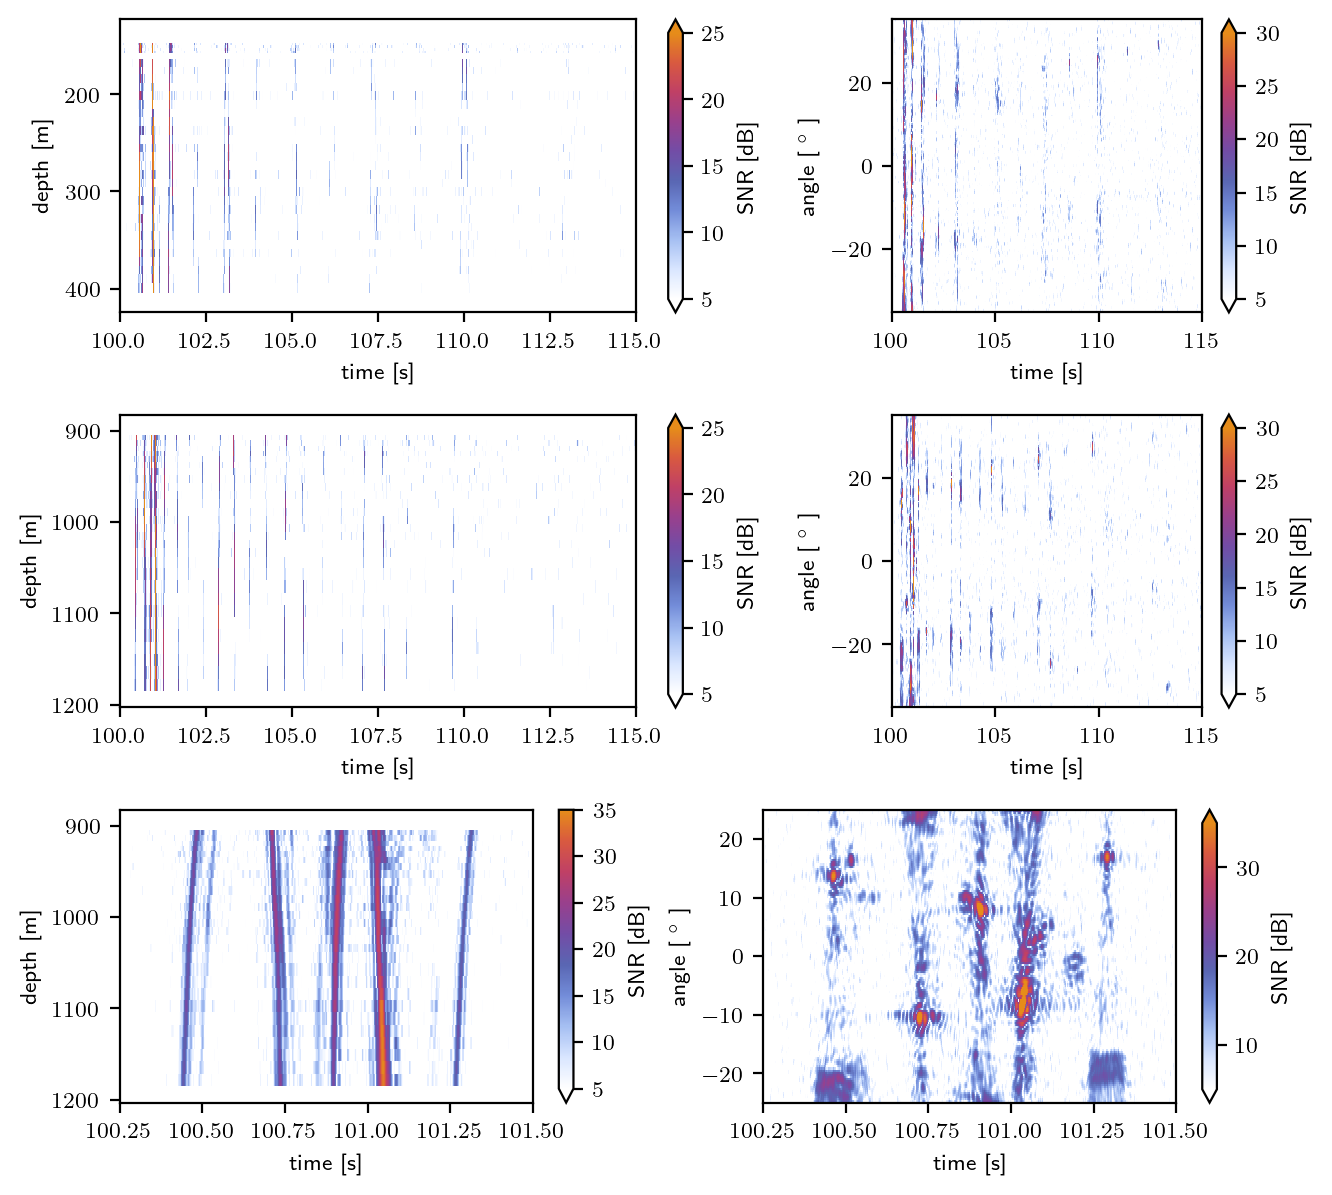

In [19]:
vlims_timefront = (7, 35)  # dB

plt.rcParams.update({"font.size": 8})
plt.rcParams.update({"text.usetex": True})

fig = plt.figure(figsize=(6.67, 6))

gs = gridspec.GridSpec(3, 10)

ax_timefront_upper = fig.add_subplot(gs[0, :6])
ax_timefront_lower = fig.add_subplot(gs[1, :6])

ax_bf_upper = fig.add_subplot(gs[0, 6:])
ax_bf_lower = fig.add_subplot(gs[1, 6:])

ax_duct_timefront = fig.add_subplot(gs[2, :5])
ax_duct_bf = fig.add_subplot(gs[2, 5:])

# Full Time-Front
##upper
plt.sca(ax_timefront_upper)
(20 * np.log10(np.abs(single_rx_upper)) - noise_power_upper_dB.values[:, None]).plot(
    x="time",
    cmap=cmps.plasma_coolwarm(),
    vmin=5,
    vmax=25,
    rasterized=True,
    cbar_kwargs={"label": "SNR [dB]"},
)
plt.xlim([100, 115])
plt.ylim([single_rx_upper.actual_depth[-1] + 25, single_rx_upper.actual_depth[0] - 25])
plt.xlabel("time [s]")
plt.ylabel("depth [m]")

##lower
plt.sca(ax_timefront_lower)
(20 * np.log10(np.abs(single_rx_lower)) - noise_power_lower_dB.values[:, None]).plot(
    x="time",
    cmap=cmps.plasma_coolwarm(),
    vmin=5,
    vmax=25,
    rasterized=True,
    cbar_kwargs={"label": "SNR [dB]"},
)
plt.xlim([100, 115])
plt.ylim([single_rx_lower.actual_depth[-1] + 25, single_rx_lower.actual_depth[0] - 25])
plt.xlabel("time [s]")
plt.ylabel("depth [m]")

# Full Beamformed Receptions
##upper
plt.sca(ax_bf_upper)
(20 * np.log10(np.abs(bf_upper)) - bf_upper_noise_dB).plot(
    x="time",
    vmin=5,
    vmax=30,
    cmap=cmps.plasma_coolwarm(),
    rasterized=True,
    cbar_kwargs={"label": "SNR [dB]"},
)
plt.xlim([100, 115])
plt.xlabel("time [s]")
plt.ylabel("angle [$\\ ^{{\\circ}} \\ $]")
##lower
plt.sca(ax_bf_lower)
(20 * np.log10(np.abs(bf_lower)) - bf_lower_noise_dB).plot(
    x="time",
    vmin=5,
    vmax=30,
    cmap=cmps.plasma_coolwarm(),
    rasterized=True,
    cbar_kwargs={"label": "SNR [dB]"},
)
plt.xlim([100, 115])
plt.xlabel("time [s]")
plt.ylabel("angle [$\\ ^{{\\circ}} \\ $]")
# Ducted Arrivals
## Timefront
plt.sca(ax_duct_timefront)
(20 * np.log10(np.abs(single_rx_lower)) - noise_power_lower_dB.values[:, None]).plot(
    x="time",
    cmap=cmps.plasma_coolwarm(),
    vmin=5,
    vmax=35,
    rasterized=True,
    cbar_kwargs={"label": "SNR [dB]"},
)
plt.xlim([100.25, 101.5])
plt.ylim([single_rx_lower.actual_depth[-1] + 25, single_rx_lower.actual_depth[0] - 25])
plt.xlabel("time [s]")
plt.ylabel("depth [m]")


# beamformer
plt.sca(ax_duct_bf)
(20 * np.log10(np.abs(bf_lower)) - bf_lower_noise_dB).plot(
    x="time",
    vmin=5,
    vmax=35,
    cmap=cmps.plasma_coolwarm(),
    rasterized=True,
    cbar_kwargs={"label": "SNR [dB]"},
)
plt.xlim([100.25, 101.5])
plt.ylim([-25, 25])
plt.tight_layout(pad=0)
plt.xlabel("time [s]")
plt.ylabel("angle [$\\ ^{{\\circ}} \\ $]")


plt.tight_layout(pad=1)

fig.savefig("../../figures/Receptions.pdf", bbox_inches="tight", dpi=500)